In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## confusion-matrix

**Confusion matrix of the emotion classifier on the test set.** Each row is normalized over its true label, so the diagonal is per-class recall. Most errors are between joy and love (0.28 of love is predicted as joy), and 0.20 of surprise is mistaken for fear.

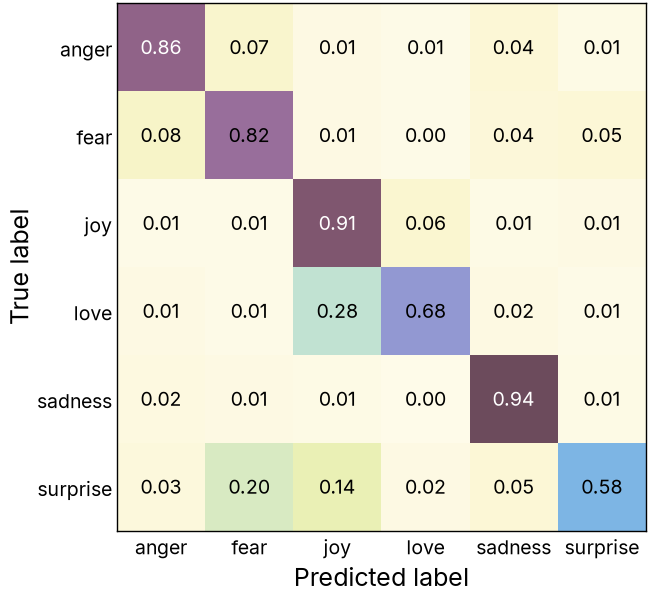

In [2]:
with open("../confusion-matrix.json") as f:
    data = json.load(f)
labels = data["labels"]
counts = np.array(data["counts"])
recall = counts / counts.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(3.25, 3.25))
im = ax.imshow(recall, aspect="auto", vmin=0, vmax=1)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = recall[i, j]
        text_color = "white" if np.dot(im.cmap(im.norm(v))[:3], [0.299, 0.587, 0.114]) < 0.5 else "black"
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color=text_color)
ax.set_xticks(range(len(labels)), labels=labels)
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.tick_params(length=0)
ax.grid(False)

fit_height(fig, ax, aspect=1.0)
fig.savefig("confusion-matrix.pdf")
fig.savefig("confusion-matrix.png")
plt.show()

## hyperparameter-grid

**Validation accuracy over learning rate and batch size.** The outlined cell marks the best setting. Learning rate 1e-4 with batch size 32 reaches the best accuracy of 0.768, while the largest learning rate, 3e-4, drops to 0.688–0.722.

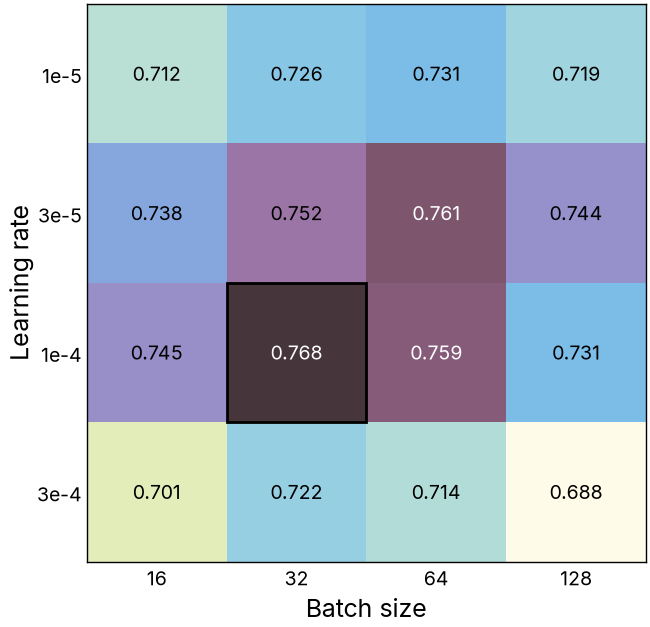

In [3]:
with open("../hyperparameter-grid.json") as f:
    data = json.load(f)
learning_rates = data["learning_rates"]
batch_sizes = data["batch_sizes"]
accuracy = np.array(data["accuracy"])

fig, ax = plt.subplots(figsize=(3.25, 3.25))
im = ax.imshow(accuracy, aspect="auto")
for i in range(len(learning_rates)):
    for j in range(len(batch_sizes)):
        v = accuracy[i, j]
        text_color = "white" if np.dot(im.cmap(im.norm(v))[:3], [0.299, 0.587, 0.114]) < 0.5 else "black"
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7, color=text_color)
best_i, best_j = np.unravel_index(accuracy.argmax(), accuracy.shape)
ax.add_patch(plt.Rectangle((best_j - 0.5, best_i - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=1))
ax.set_xticks(range(len(batch_sizes)), labels=batch_sizes)
ax.set_yticks(range(len(learning_rates)), labels=learning_rates)
ax.set_xlabel("Batch size")
ax.set_ylabel("Learning rate")
ax.tick_params(length=0)
ax.grid(False)

fit_height(fig, ax, aspect=1.0)
fig.savefig("hyperparameter-grid.pdf")
fig.savefig("hyperparameter-grid.png")
plt.show()